# Validating the Generated Datasets

In [9]:
from pathlib import Path
import numpy as np
import yaml
import matplotlib.pyplot as plt
from torchvision import datasets


In [10]:


PROJECT_ROOT = Path.cwd().parent

PROCESSED_DIR = (
    PROJECT_ROOT
    / "data"
    / "FashionMNIST"
    / "processed"
)

conditions = [100, 90, 70, 10]

In [11]:
for strength in conditions:

    dataset_dir = PROCESSED_DIR / f"correlation_{strength}"

    dataset_path = dataset_dir / "processed_dataset.npy"
    metadata_path = dataset_dir / "metadata.yaml"

    dataset = np.load(dataset_path, allow_pickle=True).item()

    images = dataset["images"]
    labels = dataset["labels"]

    with open(metadata_path, "r") as file:
        metadata = yaml.safe_load(file)

    print(f"\nCorrelation condition: {strength}%")
    print("-" * 40)
    print("Images shape:", images.shape)
    print("Labels shape:", labels.shape)
    print("Image dtype:", images.dtype)
    print("Label dtype:", labels.dtype)
    print("Image value range:", images.min(), "-", images.max())
    print("Observed correlation:", metadata["observed_correlation"])


Correlation condition: 100%
----------------------------------------
Images shape: (60000, 28, 28, 3)
Labels shape: (60000,)
Image dtype: uint8
Label dtype: int64
Image value range: 10 - 255
Observed correlation: 1.0

Correlation condition: 90%
----------------------------------------
Images shape: (60000, 28, 28, 3)
Labels shape: (60000,)
Image dtype: uint8
Label dtype: int64
Image value range: 10 - 255
Observed correlation: 0.9007166666666667

Correlation condition: 70%
----------------------------------------
Images shape: (60000, 28, 28, 3)
Labels shape: (60000,)
Image dtype: uint8
Label dtype: int64
Image value range: 10 - 255
Observed correlation: 0.6971

Correlation condition: 10%
----------------------------------------
Images shape: (60000, 28, 28, 3)
Labels shape: (60000,)
Image dtype: uint8
Label dtype: int64
Image value range: 10 - 255
Observed correlation: 0.09823333333333334


In [12]:
for strength in conditions:

    dataset_path = (
        PROCESSED_DIR
        / f"correlation_{strength}"
        / "processed_dataset.npy"
    )

    dataset = np.load(dataset_path, allow_pickle=True).item()

    images = dataset["images"]
    labels = dataset["labels"]

    assert images.shape == (60000, 28, 28, 3)
    assert labels.shape == (60000,)

    assert images.dtype == np.uint8
    assert labels.min() == 0
    assert labels.max() == 9

    print(f"{strength}% dataset: PASSED")

100% dataset: PASSED
90% dataset: PASSED
70% dataset: PASSED
10% dataset: PASSED


In [13]:
DATA_DIR = PROJECT_ROOT / "data"


try:
    print(f"Loading Fashion-MNIST from: {DATA_DIR}")

    train_dataset = datasets.FashionMNIST(
        root=str(DATA_DIR),
        train=True,
        download=False,
    )

except RuntimeError:
    print("Dataset not found. Downloading Fashion-MNIST...")

    train_dataset = datasets.FashionMNIST(
        root=str(DATA_DIR),
        train=True,
        download=True,
    )

original_images = np.array(train_dataset.data)
original_labels = np.array(train_dataset.targets)

Loading Fashion-MNIST from: /home/scinolimits/robotics/image_processing_and_computer_vision/shortcut-learning-analysis/data


/tmp/ipykernel_1191143/871885015.py:22: DeprecationWarning: __array__ implementation doesn't accept a copy keyword, so passing copy=False failed. __array__ must implement 'dtype' and 'copy' keyword arguments. To learn more, see the migration guide https://numpy.org/devdocs/numpy_2_0_migration_guide.html#adapting-to-changes-in-the-copy-keyword
  original_images = np.array(train_dataset.data)
/tmp/ipykernel_1191143/871885015.py:23: DeprecationWarning: __array__ implementation doesn't accept a copy keyword, so passing copy=False failed. __array__ must implement 'dtype' and 'copy' keyword arguments. To learn more, see the migration guide https://numpy.org/devdocs/numpy_2_0_migration_guide.html#adapting-to-changes-in-the-copy-keyword
  original_labels = np.array(train_dataset.targets)


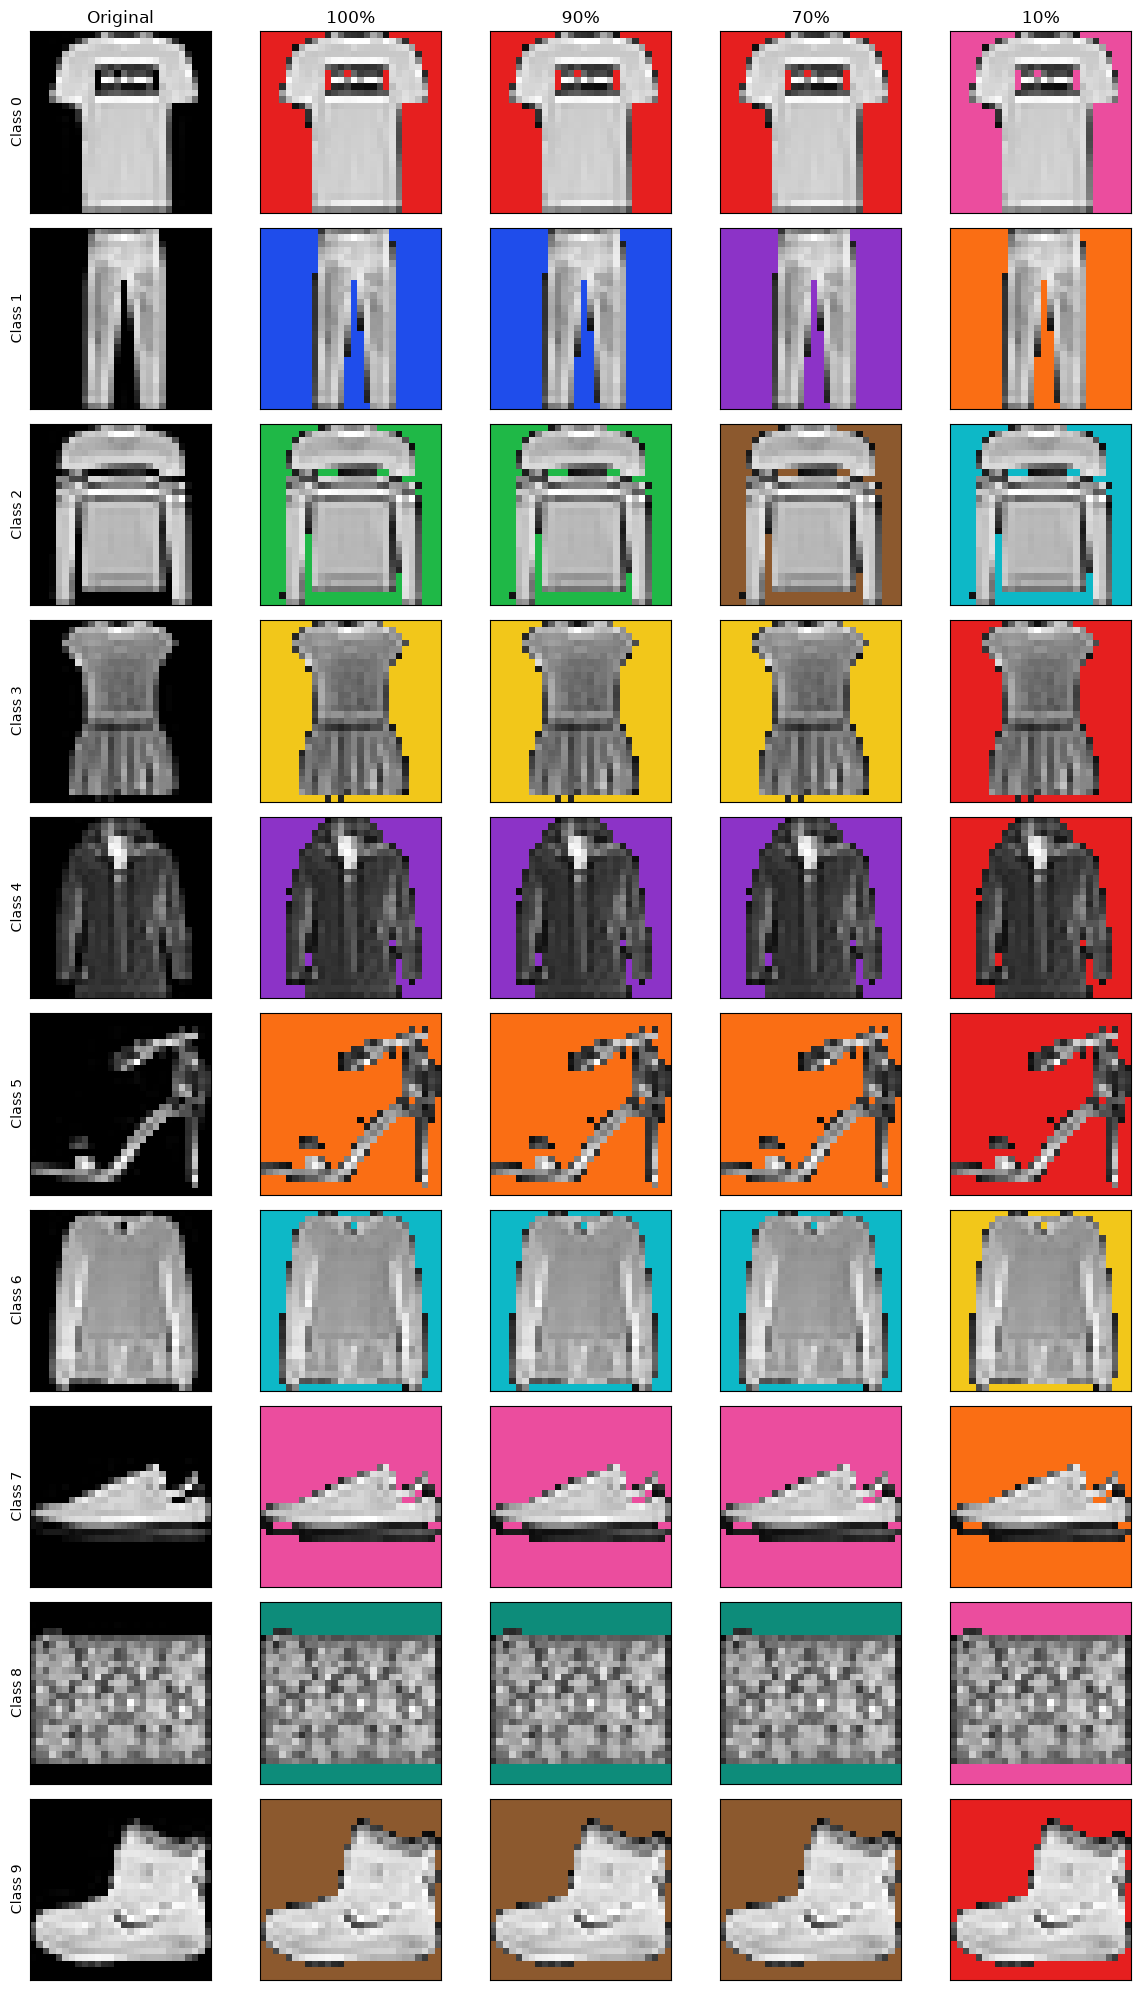

In [14]:
# Select one image from each class
sample_indices = []

for class_id in range(10):
    index = np.where(original_labels == class_id)[0][0]
    sample_indices.append(index)

fig, axes = plt.subplots(
    nrows=10,
    ncols=5,
    figsize=(12, 20)
)

for row, index in enumerate(sample_indices):

    # Original grayscale image
    axes[row, 0].imshow(original_images[index], cmap="gray")
    axes[row, 0].set_title("Original" if row == 0 else "")
    axes[row, 0].set_ylabel(f"Class {row}")

    # Transformed images
    for col, strength in enumerate(conditions, start=1):

        dataset_path = (
            PROCESSED_DIR
            / f"correlation_{strength}"
            / "processed_dataset.npy"
        )

        dataset = np.load(dataset_path, allow_pickle=True).item()

        axes[row, col].imshow(dataset["images"][index])
        axes[row, col].set_title(
            f"{strength}%" if row == 0 else ""
        )

    for ax in axes[row]:
        ax.set_xticks([])
        ax.set_yticks([])

plt.tight_layout()
plt.show()